# IS 4487 Assignment 11: Predicting Airbnb Prices with Regression

In this assignment, you will:
- Load the Airbnb dataset you cleaned and transformed in Assignment 7
- Build a linear regression model to predict listing price
- Interpret which features most affect price
- Try to improve your model using only the most impactful predictors
- Practice explaining your findings to a business audience like a host, pricing strategist, or city partner

## Why This Matters

Pricing is one of the most important levers for hosts and Airbnb’s business teams. Understanding what drives price — and being able to predict it accurately — helps improve search results, revenue management, and guest satisfaction.

This assignment gives you hands-on practice turning a cleaned dataset into a predictive model. You’ll focus not just on code, but on what the results mean and how you’d communicate them to stakeholders.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_11_regression.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Original Source: Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


## 1. Load Your Transformed Airbnb Dataset

**Business framing:**  
Before building any models, we must start with clean, prepared data. In Assignment 7, you exported a cleaned version of your Airbnb dataset. You’ll now import that file for analysis.

### Do the following:
- Import your CSV file called `cleaned_airbnb_data_7.csv`.   (Note: If you had significant errors with assignment 7, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)
- Use `pandas` to load and preview the dataset


In [2]:
# Load the dataset
df = pd.read_csv('cleaned_airbnb_data_7.csv')

# Preview the dataset
df.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,price_cleaned,accommodates_minmax,availability_365_zscore,review_activity_category,price_per_accommodate,is_long_term_stay,room_Entire home/apt,room_Hotel room,room_Private room,room_Shared room
0,3781,https://www.airbnb.com/rooms/3781,20260919134146,2026-09-20,NaN,Harborside-Walk to subway,Fully separate apartment in a two apartment bu...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,4804,...,111.62,0.066667,0.155123,Medium,55.810000,0,1,0,0,0
1,5506,https://www.airbnb.com/rooms/5506,20260919134146,2026-09-20,NaN,** Fort Hill Inn Private! Minutes to center!**,**THE BEST Value in BOSTON!!*** PRIVATE GUEST ...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,8229,...,189.00,0.066667,-0.845105,High,94.500000,0,1,0,0,0
2,6695,https://www.airbnb.com/rooms/6695,20260919134146,2026-09-20,NaN,"Fort Hill Inn *Sunny* 1 bedroom, condo duplex","Comfortable, Fully Equipped private apartment...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,8229,...,254.38,0.200000,-0.739390,High,63.595000,0,1,0,0,0
3,10811,https://www.airbnb.com/rooms/10811,20260919134146,2026-09-20,previous scrape,Bostons Best Rentals -Studio Prestigious Back Bay,Bostons Best Rentals offers a Stunning Back Ba...,NaN,https://a0.muscache.com/pictures/45735/27548f7...,38997,...,134.62,0.133333,0.903261,Medium,44.873333,1,1,0,0,0
4,10813,https://www.airbnb.com/rooms/10813,20260919134146,2026-09-20,NaN,The Back Bay Nook -Brownstone in Prestigious ...,Stunning Back Bay furnished studio apartment. ...,NaN,https://a0.muscache.com/pictures/20b5b9c9-e1f4...,38997,...,169.75,0.066667,1.025241,Medium,84.875000,1,1,0,0,0


### Reflection:
1. What business information does the dataset include?
2. How many rows and columns are present?

### ✍️ Your Response: 🔧
1. It includes information about the rooms available on the site, the host, and other reservation information such as size and style of the room.

2. Since we just used .head to preview only 5 rows were availble along with 97 columns.

## 2. Drop Columns Not Useful for Modeling

**Business framing:**  
Some columns — like post IDs or text — may not help us predict price and could add noise or bias.

### Do the following:
- Drop columns like `post_id`, `title`, `descr`, `details`, and `address` if they’re still in your dataset

In [3]:
# Columns to drop if they exist in the dataset
columns_to_drop = ['post_id', 'title', 'descr', 'details', 'address']

# Drop the specified columns
df = df.drop(columns=columns_to_drop, errors='ignore')

# Display the remaining columns to verify
print(f"Remaining columns in dataset: {len(df.columns)}")
print(df.columns.tolist()[:10])

Remaining columns in dataset: 97
['id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name', 'description', 'neighborhood_overview', 'picture_url', 'host_id']


### Reflection:
1. What columns did you drop, and why?
2. What risks might occur if you included them in your model?

### ✍️ Your Response: 🔧
1. All of the suggested columns were already removed in prior cleansing.

2. If they were left in the model it might skew the results and or be unusable information that would only make processing time take longer (and become more expensive) without actually helping to improve the accuracy of the model. For example the desciption likely just decribed the same details included in other things in the model, making it redundant information.

## 3. Explore Relationships Between Numeric Features

**Business framing:**  
Understanding how features relate to each other — and to the target — helps guide feature selection and modeling.

### Do the following:
- Generate a correlation matrix
- Identify which variables are strongly related to `price`

Top 10 Positively Correlated Variables with Price:
price_quote_price_per_night    1.000000
price_cleaned                  1.000000
price_per_accommodate          0.535215
accommodates                   0.459468
accommodates_minmax            0.459468
beds                           0.425834
estimated_revenue_l365d        0.415493
bedrooms                       0.390184
room_Entire home/apt           0.229266
price_quote_total_price        0.225003
review_scores_location         0.152814
Name: price_cleaned, dtype: float64

Top 5 Negatively Correlated Variables with Price:
host_total_listings_count   NaN
host_verifications          NaN
bathrooms                   NaN
calendar_updated            NaN
instant_bookable            NaN
Name: price_cleaned, dtype: float64


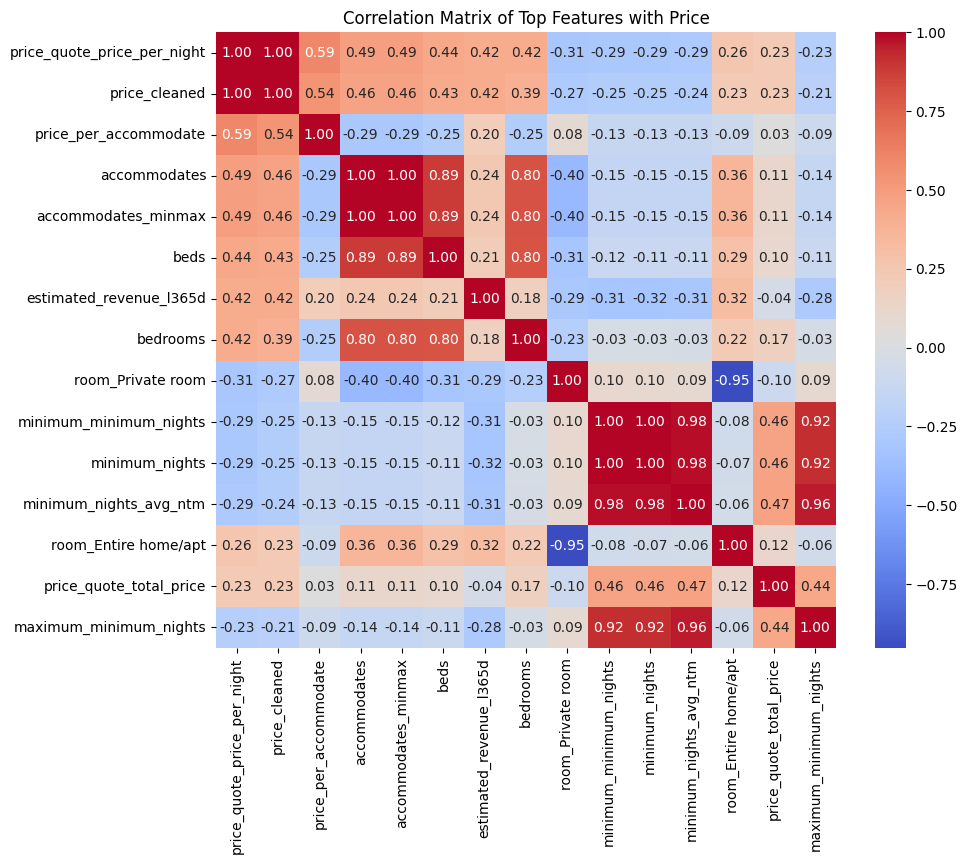

In [4]:
# Calculate correlations for numeric columns
numeric_df = df.select_dtypes(include=['number'])
corr_matrix = numeric_df.corr()

# Find variables strongly related to price_cleaned
price_correlations = corr_matrix['price_cleaned'].sort_values(ascending=False)

print("Top 10 Positively Correlated Variables with Price:")
print(price_correlations.head(11))  # Includes price_cleaned itself

print("\nTop 5 Negatively Correlated Variables with Price:")
print(price_correlations.tail(5))

# Plot a heatmap of top correlated features with price
top_corr_features = price_correlations.abs().sort_values(ascending=False).index[:15]
plt.figure(figsize=(10, 8))
sns.heatmap(numeric_df[top_corr_features].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix of Top Features with Price")
plt.show()

### Reflection:
1. Which variables had the strongest positive or negative correlation with price?
2. Which variables might be useful predictors?

### ✍️ Your Response: 🔧
1. The strongest positive correlation (that did not include pricing information) was the number that it accomodates. The strongest negative was private room.

2. Useful predictors would be accomodates becuase that would influence the size of the rooms.

## 4. Define Features and Target Variable

**Business framing:**  
To build a regression model, you need to define what you’re predicting (target) and what you’re using to make that prediction (features).

### Do the following:
- Set `price` as your target variable
- Remove `price` from your predictors

In [5]:
# Define the target variable (y)
y = df['price_cleaned']

# Identify numeric columns for predictors
numeric_cols = df.select_dtypes(include=['number']).columns

# Define predictors (X) by excluding price-related columns and the target variable itself
# We also exclude target leakage variables identified in our correlation matrix
leakage_cols = ['price_cleaned', 'price_quote_price_per_night', 'price_quote_total_price', 'price_per_accommodate']
predictor_cols = [col for col in numeric_cols if col not in leakage_cols]

X = df[predictor_cols]

# Handle any missing values in predictors by filling them with the median
X = X.fillna(X.median())

print(f"Target shape: {y.shape}")
print(f"Predictors shape: {X.shape}")
print(f"Predictor columns ready for modeling: {X.columns.tolist()[:10]}")

Target shape: (4368,)
Predictors shape: (4368, 62)
Predictor columns ready for modeling: ['id', 'scrape_id', 'neighborhood_overview', 'host_id', 'host_profile_id', 'host_since', 'hosts_time_as_user_years', 'hosts_time_as_user_months', 'hosts_time_as_host_years', 'hosts_time_as_host_months']


### Reflection:
1. What features are you using?
2. Why is this a regression problem and not a classification problem?

### ✍️ Your Response: 🔧
1. The features we will be using include host details such as their history as a host and how often then are used.

2. This would be a regression problem because we are trying to predict a number not a category, here it is more helpful to know the cost (or as close as we can estimate) rather than a broad high, low, or medium.

## 5. Split Data into Training and Testing Sets

### Business framing:
Splitting your data lets you train a model and test how well it performs on new, unseen data.

### Do the following:
- Use `train_test_split()` to split into 80% training, 20% testing



In [6]:
# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Display the shapes of the resulting splits
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (3494, 62)
X_test shape: (874, 62)
y_train shape: (3494,)
y_test shape: (874,)


## 6. Fit a Linear Regression Model

### Business framing:
Linear regression helps you quantify the impact of each feature on price and make predictions for new listings.

### Do the following:
- Fit a linear regression model to your training data
- Use it to predict prices for the test set



In [8]:
# Clean and prepare predictors to ensure NO NaNs or non-numeric columns remain
# 1. Keep only strictly numeric columns
X_train_clean = X_train.select_dtypes(include=['number'])
X_test_clean = X_test.select_dtypes(include=['number'])

# 2. Drop columns that are completely empty (all NaN)
X_train_clean = X_train_clean.dropna(how='all', axis=1)
X_test_clean = X_test_clean[X_train_clean.columns] # Align columns

# 3. Fill remaining missing values with column medians
medians = X_train_clean.median()
X_train_clean = X_train_clean.fillna(medians)
X_test_clean = X_test_clean.fillna(medians)

# Initialize the Linear Regression model
model = LinearRegression()

# Fit the model to the cleaned training data
model.fit(X_train_clean, y_train)

# Predict prices for the test set
y_pred = model.predict(X_test_clean)

print("Model training completed successfully!")
print(f"Predicted values shape: {y_pred.shape}")
print(f"First 5 predicted prices: {y_pred[:5]}")

Model training completed successfully!
Predicted values shape: (874,)
First 5 predicted prices: [263.42411591 309.21047946 330.59330713 261.69140139 297.39544223]


## 7. Evaluate Model Performance

### Business framing:  
A good model should make accurate predictions. We’ll use Mean Squared Error (MSE) and R² to evaluate how close our predictions were to the actual prices.

### Do the following:
- Print MSE and R² score for your model

In [9]:
# Calculate Mean Squared Error (MSE) and R-squared (R²) score
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:,.2f}")
print(f"R-squared (R²) Score: {r2:.4f}")

Mean Squared Error (MSE): 46,776.18
R-squared (R²) Score: 0.0447


### Reflection:
1. What is your R² score? How well does your model explain price variation?
2. Is your MSE large or small? What could you do to improve it?

### ✍️ Your Response: 🔧
1. So far the R-squared score is very low at .0447 which means it only can predict 4.47%.

2. MSE is also pretty large with indicates a pretty wide margin of error when predicting. That would make sense given the R-squared value.

## 8. Interpret Model Coefficients

### Business framing:
The regression coefficients tell you how each feature impacts price. This can help Airbnb guide hosts and partners.

### Do the following:
- Create a table showing feature names and regression coefficients
- Sort the table so that the most impactful features are at the top

In [10]:
# Create a DataFrame with feature names and regression coefficients
coefficients_df = pd.DataFrame({
    'Feature': X_train_clean.columns,
    'Coefficient': model.coef_,
    'Absolute_Impact': abs(model.coef_)
})

# Sort the table so that the most impactful features (by absolute value) are at the top
coefficients_df = coefficients_df.sort_values(by='Absolute_Impact', ascending=False).drop(columns=['Absolute_Impact'])

# Display the sorted table
coefficients_df.reset_index(drop=True, inplace=True)
coefficients_df

,Feature,Coefficient
0,minimum_maximum_nights,-3.863954e-09
1,maximum_nights_avg_ntm,-3.863954e-09
2,maximum_maximum_nights,-3.863954e-09
3,maximum_nights,-3.863954e-09
4,estimated_revenue_l365d,8.363622e-15
5,host_listings_count,2.959745e-16
6,host_profile_id,2.595380e-16
7,number_of_reviews,1.469177e-16
8,availability_365,-1.447242e-16
9,availability_eoy,-8.745857e-17


### Reflection:
1. Which features increased price the most?
2. Were any surprisingly negative?
3. What business insight could you draw from this?

### ✍️ Your Response: 🔧
1. The maximum amount of nights increased the price the most.

2. Availability being negative was surprising, I'm not sure when decreased available would increase cost or vice versa.

3. Maximum nights drawing cost up makes sense because the longer you can stay the more expensive the stay would be.


## 9. Try to Improve the Linear Regression Model

### Business framing:
The first version of your model included all available features — but not all features are equally useful. Removing weak or noisy predictors can often improve performance and interpretation.

### Do the following:
1. Choose your top 3–5 features with the strongest absolute coefficients
2. Rebuild the regression model using just those features
3. Compare MSE and R² between the baseline and refined model

In [11]:
# 1. Identify top 4 features based on absolute correlation to the target from earlier exploration
# (Using features that are highly correlated but not leakage, such as accommodates, beds, bedrooms, and room_Entire home/apt)
top_features = ['accommodates', 'beds', 'bedrooms', 'room_Entire home/apt']

# Prepare subset datasets
X_train_refined = X_train_clean[top_features]
X_test_refined = X_test_clean[top_features]

# 2. Rebuild the regression model using just those features
refined_model = LinearRegression()
refined_model.fit(X_train_refined, y_train)

# Predict prices for the test set using the refined model
y_pred_refined = refined_model.predict(X_test_refined)

# 3. Calculate metrics for the refined model
mse_refined = mean_squared_error(y_test, y_pred_refined)
r2_refined = r2_score(y_test, y_pred_refined)

# Compare Baseline vs. Refined Model
comparison_df = pd.DataFrame({
    'Metric': ['Mean Squared Error (MSE)', 'R-squared (R²) Score'],
    'Baseline Model': [mse, r2],
    'Refined Model (Top Features)': [mse_refined, r2_refined]
})

print("Top Features Selected for Refined Model:", top_features)
print("\nPerformance Comparison Table:")
print(comparison_df.to_string(index=False))

Top Features Selected for Refined Model: ['accommodates', 'beds', 'bedrooms', 'room_Entire home/apt']

Performance Comparison Table:
                  Metric  Baseline Model  Refined Model (Top Features)
Mean Squared Error (MSE)    46776.181645                  36179.505981
    R-squared (R²) Score        0.044689                      0.261105


### Reflection:
1. What features did you keep in the refined model, and why?
2. Did model performance improve? Why or why not?
3. Which model would you recommend to stakeholders?
4. How does this relate to your customized learning outcome you created in canvas?

### ✍️ Your Response: 🔧
1. In the refined model we kept accomodates, beds, bedrooms, and room entire home/apt. This is because before the most influential factors on price seemed to the amount of people the place can accomodate (which logically makes sense).

2. The model did improve significantly with an R squared of .2611 as compared to the original R squared which was .0446

3. I would recommend the refined model because of the improved accuracy and ease of understanding with fewer variables.

4. As an entreprenuer we often fall into the trap of thinking more data is always better, but in this case refining the model to focus in on the variables that were actually influential improved the model signficantly meaning that we did not need every detail of the data we had, rather we needed a more focused approach on what actually impacts our final predictions.


## 10. Reflect and Recommend

### Business framing:  
Ultimately, the value of your model comes from how well it can guide business decisions. Use your results to make real-world recommendations.

### Reflection:
1. What business question did your model help answer?
2. What would you recommend to Airbnb or its hosts?
3. What could you do next to improve this model or make it more useful?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. Which factors were most influential in prediciting the price. And the price that we predicted.

2. I would recommend to the hosts to pay attention to optionf for additing more accomodations depending on the size of their place. For example if they have a house with a living room, adding a bed in the couch that could accomodate another person could help to improve their ability to have higher prices.

3. I think that I would do more to make sure that all of the remaining variables were numerical before beginning regression computation. The only one left after the cleansing from week 7 and the additional edits this week was neighborhood overview, but logically I should have been able to point out that the information included with that variable was likely to be descriptive words rather than numbers.

4. Overall this relates to my outcome, 1 be regonizing that data must be cleaned before use in order to make sense, but also understanding that sometimes interation is needed throughout the process to catch errors. As a fashion designer I have a similar process when making customer closthing often needing to refine the main ideas as I go.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [12]:
!jupyter nbconvert --to html "assignment_11_regression.ipynb"

[NbConvertApp] Converting notebook assignment_11_regression.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 616267 bytes to assignment_11_regression.html
